Gurobi is not only an LP and MIP solver. This page builds four small models that step past straight
lines: a quadratic objective, quadratic constraints, a curved objective approximated by straight
pieces, and a model with several objectives ranked by priority. Each is written the same way as an
LP; what changes is what the solver has to do with it.

To run it yourself: `pip install gurobipy numpy pandas matplotlib`. The free licence that comes with
`pip install gurobipy` is enough for everything here.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import gurobipy as gp
from gurobipy import GRB

## A quadratic objective

$$\begin{aligned} \min\ & x^2 + xy + y^2 + yz + z^2 + 2x \\ \text{s.t.}\ & x + 2y + 3z \ge 4 \\ & x + y \ge 1 \\ & x,\ y,\ z \ge 0 \end{aligned}$$

Products of variables are typed as products. Gurobi sees the objective is quadratic and treats the
model as a QP.

In [2]:
qp = gp.Model("qp")
qp.Params.OutputFlag = 0
x, y, z = [qp.addVar(name=n) for n in "xyz"]
qp.setObjective(x * x + x * y + y * y + y * z + z * z + 2 * x, GRB.MINIMIZE)
qp.addConstr(x + 2 * y + 3 * z >= 4)
qp.addConstr(x + y >= 1)
qp.update()
print("IsQP =", qp.IsQP)

Restricted license - for non-production use only - expires 2027-11-29


IsQP = 1


**Predict:** the $2x$ term makes $x$ costly. Will $x$ be zero at the optimum?

In [3]:
qp.optimize()
print(f"objective = {qp.ObjVal:.4f} | x, y, z = {x.X:.4f}, {y.X:.4f}, {z.X:.4f}")

objective = 2.1111 | x, y, z = 0.0000, 1.0000, 0.6667


Now require whole numbers. Changing each variable's `VType` turns the QP into a mixed-integer QP.
**Predict:** can the objective go down?

In [4]:
for v in (x, y, z):
    v.VType = GRB.INTEGER
qp.optimize()
print(f"objective = {qp.ObjVal:.4f} | x, y, z = {x.X:.0f}, {y.X:.0f}, {z.X:.0f}")

objective = 3.0000 | x, y, z = 0, 1, 1


## Quadratic constraints: two cones

$$\begin{aligned} \max\ & x \\ \text{s.t.}\ & x + y + z = 1 \\ & x^2 + y^2 \le z^2 \\ & x^2 \le yz \\ & x,\ y,\ z \ge 0 \end{aligned}$$

With $z \ge 0$, $x^2 + y^2 \le z^2$ says the point $(x, y)$ lies within distance $z$ of the origin: a
second-order cone. $x^2 \le yz$ with $y, z \ge 0$ is a rotated cone. Both regions are convex, even
though $-z^2$ and $-yz$ look like trouble on their own.

In [5]:
qc = gp.Model("qcp")
qc.Params.OutputFlag = 0
x, y, z = [qc.addVar(name=n) for n in "xyz"]
qc.setObjective(x, GRB.MAXIMIZE)
qc.addConstr(x + y + z == 1, name="sum")
cone = qc.addConstr(x * x + y * y - z * z <= 0, name="cone")
rotated = qc.addConstr(x * x - y * z <= 0, name="rotated_cone")
qc.update()
print(qc.NumConstrs, "linear constraint,", qc.NumQConstrs, "quadratic constraints")

1 linear constraint, 2 quadratic constraints


**Predict:** $x$ has to share a total of 1 with $y$ and $z$. Can it reach $\tfrac{1}{2}$?

In [6]:
qc.optimize()
print(f"x = {x.X:.4f}, y = {y.X:.4f}, z = {z.X:.4f} | IsMIP = {qc.IsMIP}")

x = 0.3270, y = 0.2571, z = 0.4159 | IsMIP = 0


### When a quadratic constraint is not convex

Flip the first cone to $x^2 + y^2 \ge z^2$. The points *outside* a cone do not form a convex set, so
the solver can no longer rely on any local optimum being the best one. Before version 11, Gurobi
stopped with an error here unless you set the parameter `NonConvex = 2`. Setting it to 1 brings that
behaviour back:

In [7]:
qc.remove(cone)
qc.addConstr(x * x + y * y - z * z >= 0, name="outside_cone")
qc.Params.NonConvex = 1
try:
    qc.optimize()
except gp.GurobiError as err:
    print("error", err.errno, ":", err)

error 10020 : Constraint Q not PSD (negative diagonal entry). Set NonConvex parameter to -1 or 2 to solve model.


Back to the default (`-1`), which in current Gurobi accepts non-convex quadratics and searches for the
global optimum by branching, the way it does for a MIP. **Predict:** is the new optimum above or below
the cone answer?

In [8]:
qc.Params.NonConvex = -1
qc.optimize()
print(f"x = {x.X:.4f}, y = {y.X:.4f}, z = {z.X:.4f} | IsMIP = {qc.IsMIP}")

x = 0.3333, y = 0.3333, z = 0.3333 | IsMIP = 1


## Piecewise-linear objectives

$$\begin{aligned} \min\ & f(x) - y + g(z) \\ \text{s.t.}\ & x + 2y + 3z \le 4 \\ & x + y \ge 1 \\ & 0 \le x,\ y,\ z \le 1 \end{aligned} \qquad \begin{aligned} f(x) &= e^{-x} \\ g(z) &= 2z^2 - 4z \end{aligned}$$

Instead of the curves, give Gurobi points on them. It joins the points with straight segments, so
the objective becomes piecewise linear. Here are 101 points between 0 and 1.

In [9]:
u = np.linspace(0, 1, 101)
f = np.exp(-u)
g = 2 * u**2 - 4 * u
print(len(u), "breakpoints | f from", f[0], "to", round(f[-1], 4), "| g from", g[0], "to", g[-1])

101 breakpoints | f from 1.0 to 0.3679 | g from 0.0 to -2.0


The two functions, and the negation of $f$ that comes next. A minimisation with a convex
piecewise-linear objective is still an LP; with a concave piece, it is not.

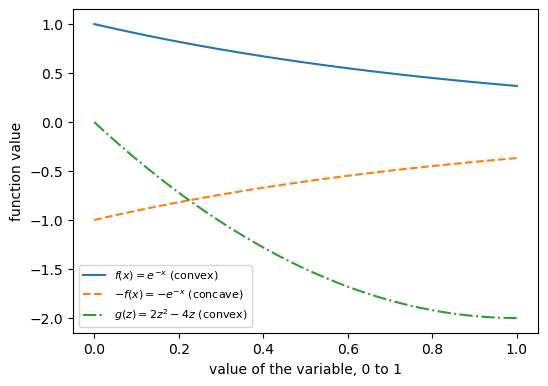

In [10]:
fig, ax = plt.subplots(figsize=(6, 4.2))
ax.plot(u, f, label=r"$f(x) = e^{-x}$ (convex)")
ax.plot(u, -f, "--", label=r"$-f(x) = -e^{-x}$ (concave)")
ax.plot(u, g, "-.", label=r"$g(z) = 2z^2 - 4z$ (convex)")
ax.set(xlabel="value of the variable, 0 to 1", ylabel="function value")
ax.legend(fontsize=8)
plt.show()
# alt: On 0 to 1, e^{-x} falls from 1 to 0.37 bending upward, its negation rises from -1 to -0.37 bending downward, and 2z^2 - 4z falls from 0 to -2 bending upward.

`setPWLObj` attaches a piecewise-linear objective term to one variable; the linear $-y$ goes in the
ordinary `Obj` attribute.

In [11]:
pw = gp.Model("pwl")
pw.Params.OutputFlag = 0
x, y, z = [pw.addVar(ub=1, name=n) for n in "xyz"]
pw.addConstr(x + 2 * y + 3 * z <= 4)
pw.addConstr(x + y >= 1)
y.Obj = -1
pw.setPWLObj(x, u, f)
pw.setPWLObj(z, u, g)
pw.update()
print(pw.NumVars, "variables,", pw.NumConstrs, "constraints, minimise")

3 variables, 2 constraints, minimise


**Predict:** $f$ falls as $x$ grows and $g$ falls as $z$ grows, but the first constraint caps them.
Where do $x$, $y$ and $z$ land?

In [12]:
pw.optimize()
print(f"objective = {pw.ObjVal:.4f} | x, y, z = {x.X:.4f}, {y.X:.4f}, {z.X:.4f} | IsMIP = {pw.IsMIP}")

objective = -1.9346 | x, y, z = 0.6900, 0.7250, 0.6200 | IsMIP = 0


Now replace $f$ with $-f$, the concave curve in the figure. **Predict:** does the solution move, and
does Gurobi still solve it as an LP?

In [13]:
pw.setPWLObj(x, u, -f)
pw.optimize()
print(f"objective = {pw.ObjVal:.4f} | x, y, z = {x.X:.4f}, {y.X:.4f}, {z.X:.4f} | IsMIP = {pw.IsMIP}")

objective = -3.7777 | x, y, z = 0.0000, 1.0000, 0.6667 | IsMIP = 1


## Multiple objectives, ranked

Twenty elements; pick at most 12. Four sets each want as many of their own elements picked as
possible. The sets do not matter equally: set 1 has the highest priority, sets 2 and 3 share the
next, set 4 comes last.

In [14]:
sets = np.array([
    [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
    [0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1],
    [0, 0, 0, 1, 1, 0, 1, 1, 0, 0, 0, 0, 0, 1, 1, 0, 1, 1, 0, 0],
    [0, 0, 0, 1, 1, 1, 0, 0, 0, 1, 1, 1, 0, 0, 0, 1, 1, 1, 0, 0]])
priority = [3, 2, 2, 1]
weight = [1.0, 0.25, 1.25, 1.0]
print("elements in each set:", sets.sum(axis=1), "| budget: 12")

elements in each set: [10 10  8  9] | budget: 12


`setObjectiveN` adds one objective at a time. Gurobi optimises the highest priority first, then the
next while holding the first near its best. "Near" is set by `abstol` and `reltol`: how much each
objective may give up for the ones below it. Objectives with the same priority are added together
using their weights.

In [15]:
mo = gp.Model("multiobj")
mo.Params.OutputFlag = 0
pick = mo.addMVar(20, vtype=GRB.BINARY, name="pick")
mo.addConstr(pick.sum() <= 12, name="budget")
mo.ModelSense = GRB.MAXIMIZE
for i in range(4):
    mo.setObjectiveN(sets[i] @ pick, index=i, priority=priority[i], weight=weight[i],
                     abstol=i + 1, reltol=0.01, name=f"set{i + 1}")
mo.update()
print(mo.NumObj, "objectives,", mo.NumVars, "binary variables")

4 objectives, 20 binary variables


**Predict:** set 1 has 10 elements and the budget is 12. How many of set 1's elements will be picked?
`PoolSolutions` asks Gurobi to keep up to 100 of the solutions it finds, not just the best.

In [16]:
mo.Params.PoolSolutions = 100
mo.optimize()
print("picked elements:", [e + 1 for e in range(20) if pick.X[e] > 0.5])
for i in range(4):
    mo.Params.ObjNumber = i
    print(f"set{i + 1}: {mo.ObjNVal:.0f} of {sets[i].sum()} covered")

picked elements: [2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 17]
set1: 9 of 10 covered
set2: 6 of 10 covered
set3: 5 of 8 covered
set4: 7 of 9 covered


### The solution pool

Each pooled solution is read by setting `SolutionNumber`; `ObjNVal` then gives that solution's value
of the objective chosen by `ObjNumber`. Here are up to the first 10.

In [17]:
print("solutions in the pool:", mo.SolCount)
rows = []
for k in range(min(10, mo.SolCount)):
    mo.Params.SolutionNumber = k
    row = {}
    for i in range(4):
        mo.Params.ObjNumber = i
        row[f"set{i + 1}"] = mo.ObjNVal
    rows.append(row)
pd.DataFrame(rows).astype(int)

solutions in the pool: 3


,set1,set2,set3,set4
0,9,6,5,7
1,9,7,7,6
2,10,5,4,4


Questions to try:

- In the QP, requiring whole numbers raised the minimum. Could adding integer requirements ever
  lower it?
- In the piecewise-linear model, why does a concave piece force Gurobi to add binary variables, while
  a convex one does not?
- Row 2 of the pool covers all 10 elements of set 1, yet Gurobi returned a solution covering 9.
  Which setting allowed that? Change it for set 1 and re-solve.